# M04-2 | conv + BN in QAT: BN Stays, and a Separate Folded Copy Is Made for Weight Quantization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m04_conv_bn_folding/02_qat_graph_structure.ipynb)

PTQ folds BN into conv at `prepare_pt2e` (M04-1). QAT cannot do this: during training BN must keep using the **current batch's statistics**,
and if it is folded there is no BN left to train. But we also want the weight's fake quant to quantize the "folded weight", so that the quantization error seen in training matches deployment.

`prepare_qat_pt2e` does this by inserting a small subgraph around the conv and BN. The full reasoning for why it is inserted this way is in the section "QAT: Which Weight Should the Weight's Fake Quant Quantize"
of the M04 overview, sourced from the blog post "[Convolution and BatchNorm Fusion](https://bobondemon.github.io/2025/05/04/Convolution-%E8%88%87-BatchNorm-%E7%9A%84%E8%9E%8D%E5%90%88%E5%A4%A7%E6%B3%95/)" (in Chinese);
this notebook maps that reasoning onto the graph.

- **A.** For the same conv_bn_relu: how the graphs from `prepare_pt2e` and `prepare_qat_pt2e` differ.
- **B.** Reading the QAT subgraph: why it is inserted this way and what each extra op computes.
- **C.** After `convert_pt2e`: QAT's BN is folded too; and when folding fails.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m04_conv_bn_folding")

In [2]:
import copy
from collections import Counter

import torch
import torch.nn.functional as F

from common.graph_utils import qdq_nodes, short
from common.models import ConvBnReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, prepare_qat_pt2e, quiet
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)

As in M04-1, first give BN real running stats. QAT must export with the training IR (`export_module(..., train=True)`)
so that BN is the training version of the op; the quantizer must be passed `is_qat=True` so that fake quant is what gets inserted:

In [3]:
model = ConvBnReLU(3, 8).train()
with torch.no_grad():
    for _ in range(5):
        model(torch.randn(16, 3, 16, 16) * 2 + 1)

ptq = prepare_pt2e(export_module(copy.deepcopy(model).eval(), example_inputs()),
                   get_xnnpack_quantizer(is_per_channel=True)[0])
qat = prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True),
                       get_xnnpack_quantizer(is_per_channel=True, is_qat=True)[0])

## A. How the Graphs from prepare_pt2e and prepare_qat_pt2e Differ

Which ops each graph has and how many (`call_module` is written as the module class):

In [4]:
def op_counter(g):
    return Counter(type(g.get_submodule(n.target)).__name__ if n.op == "call_module" else short(n.target)
                   for n in g.graph.nodes if n.op in ("call_function", "call_module") and n.name != "_guards_fn")


c_ptq, c_qat = op_counter(ptq), op_counter(qat)
table([[k, c_ptq.get(k, 0), c_qat.get(k, 0)] for k in sorted(set(c_ptq) | set(c_qat))], ["op", "prepare_pt2e", "prepare_qat_pt2e"])

op,prepare_pt2e,prepare_qat_pt2e
FusedMovingAvgObsFakeQuantize,0,3
HistogramObserver,2,0
PerChannelMinMaxObserver,1,0
add,0,1
add_,0,1
batch_norm,0,1
conv2d,1,1
div,0,2
mul,0,1
relu,1,1


In [5]:
assert c_ptq["batch_norm"] == 0 and c_qat["batch_norm"] == 1
assert c_qat["FusedMovingAvgObsFakeQuantize"] == 3

- **PTQ**: `batch_norm` is already folded; the quantization points are three observers (they only collect statistics and do not change values).
- **QAT**: `batch_norm` is still there, with the extra chain of ops `mul`, `div`, `sqrt`, `reshape` that computes the BN scale; the quantization points are three `FusedMovingAvgObsFakeQuantize` (which really fake-quantize).
  The "fused" in its name has nothing to do with this chapter's conv + BN; it means that "update min/max, compute scale/zero point, quantize → dequantize" are merged into one ATen kernel. The way this kernel computes scale has a pitfall, handled in M06-3.
- The quantization points are in the same places: input `x`, the weight, and the relu output. What differs is what the weight's one quantizes; see section B.
- `add_` is BN's `num_batches_tracked += 1`, present in every train-mode export (M00-2).

## B. Reading the QAT Subgraph

First a recap of the overview's conclusions ($\sigma$ is the standard deviation with $\varepsilon$ included; subscript $B$ means this batch's statistics, no subscript means running stats):

- **The weight's fake quant should quantize $W_{\text{inf}} = \gamma W / \sigma$**: it is the weight actually quantized at deployment, and the running stats change slowly, so the quantization grid does not jump every batch.
  If it quantized $W_{\text{train}} = \gamma W / \sigma_B$ instead, the grid would jump with $\sigma_B$ and training would be unstable.
- **BN must still train with batch statistics**. The whitepaper's "slow version" computes an extra unquantized conv to get $\mu_B$, $\sigma_B$;
  PyTorch's default "approximate version" `_forward_approximate` saves that conv, and `prepare_qat_pt2e` uses it:

$$
s = \frac{\gamma}{\sigma}, \qquad
y = \mathrm{BN}_{\text{batch}}\!\Big( \frac{\mathrm{conv}\big(\mathrm{fq}(x),\ \mathrm{fq}(W \cdot s)\big)}{s} \Big) \tag{1}
$$

Draw the whole QAT graph, with each term of Eq. (1) annotated under its node:

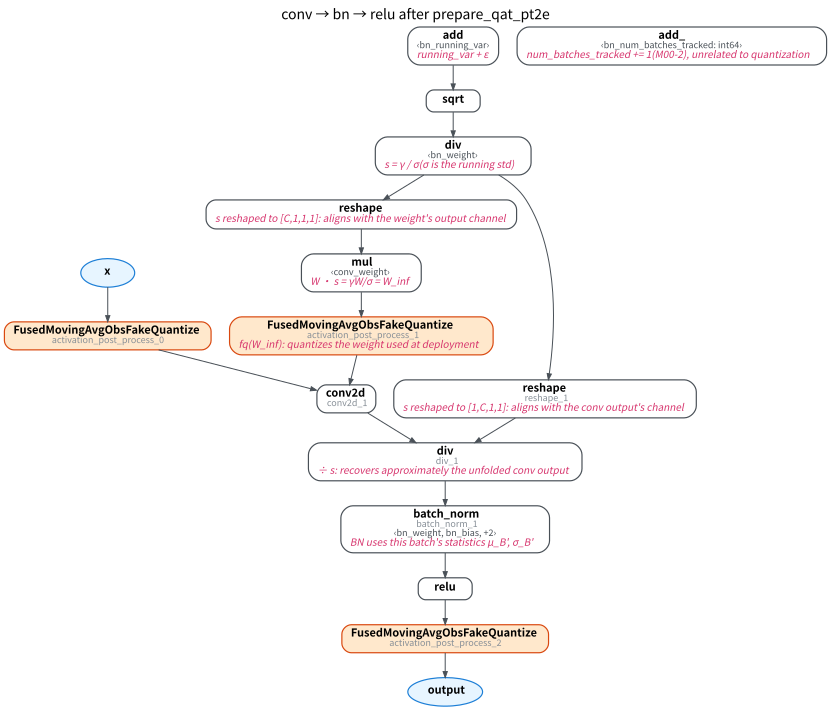

In [6]:
nodes = {n.name: n for n in qat.graph.nodes}
fq_w = next(n for n in qat.graph.nodes if n.op == "call_module" and n.args[0].target == torch.ops.aten.mul.Tensor)
notes = {
    "add": "running_var + ε",
    "add_": "num_batches_tracked += 1(M00-2), unrelated to quantization",
    "div": "s = γ / σ(σ is the running std)",
    "reshape": "s reshaped to [C,1,1,1]: aligns with the weight's output channel",
    "mul": "W · s = γW/σ = W_inf",
    fq_w.name: "fq(W_inf): quantizes the weight used at deployment",
    "reshape_1": "s reshaped to [1,C,1,1]: aligns with the conv output's channel",
    "div_1": "÷ s: recovers approximately the unfolded conv output",
    "batch_norm_1": "BN uses this batch's statistics μ_B', σ_B'",
}
draw(qat, notes=notes, title="conv → bn → relu after prepare_qat_pt2e")

In [7]:
assert nodes["batch_norm_1"].args[0] is nodes["div_1"]  # BN takes the conv output after ÷ s
assert fq_w.args[0] is nodes["mul"]  # the weight's fake quant takes W · s

Reading from top to bottom:

1. `add` → `sqrt` → `div` computes the per-channel $s = \gamma/\sigma$ from the running var.
2. `reshape` → `mul` computes $W \cdot s = W_{\text{inf}}$ and hands it to the weight's fake quant. The conv itself has no bias; BN's $\beta$ is added later.
3. The conv output is computed with the folded weight, so it is "already multiplied by $s$". `reshape_1` → `div_1` divides by $s$ again, recovering approximately the output of the unfolded conv.
4. After recovery, the following `batch_norm` works as if nothing were quantized: it computes this batch's mean $\mu_B'$ and standard deviation $\sigma_B'$ from its input to normalize, and updates the running stats as usual.

**Why divide by $s$ in step 3?** Expand the BN in step 4 ($z$ is the output of the quantized conv):

$$
\gamma\,\frac{z/s - \mu_B'}{\sigma_B'} + \beta
= z \cdot \frac{\sigma}{\sigma_B'} + \Big(\beta - \frac{\gamma\,\mu_B'}{\sigma_B'}\Big) \tag{2}
$$

The right-hand side is exactly the slow version's formula: the conv with quantized $W_{\text{inf}}$, multiplied by the correction term $\sigma/\sigma_B'$, plus the bias from batch statistics.
Dividing by $s$ lets BN compute the correction term itself, so no extra unquantized conv is needed; the cost is that $\mu_B'$, $\sigma_B'$ come from the **quantized** conv output, not the unquantized one the slow version uses.

Verify that both sides of Eq. (2) are equal, using the fake quant modules and parameters in the graph:

In [8]:
params = dict(qat.named_parameters())
fq_x_mod = copy.deepcopy(qat.get_submodule(nodes["conv2d_1"].args[0].target))  # a copy: fake quant updates its state during forward
fq_w_mod = copy.deepcopy(qat.get_submodule(fq_w.target))
w, gamma, beta = params["conv.weight"], params["bn.weight"], params["bn.bias"]
sigma = torch.sqrt(qat.get_buffer("bn.running_var") + 1e-5)  # running std, including ε (BatchNorm2d default 1e-5)
s = gamma / sigma

x = torch.randn(16, 3, 16, 16) * 2 + 1
with torch.no_grad():
    z = F.conv2d(fq_x_mod(x), fq_w_mod(w * s.reshape(-1, 1, 1, 1)), None, padding=1)  # output of the quantized conv
    u = z / s.reshape(1, -1, 1, 1)
    left = F.batch_norm(u, None, None, gamma, beta, training=True, eps=1e-5)  # left side of Eq. (2): what the graph does
    mu_b, sigma_b = u.mean((0, 2, 3)), torch.sqrt(u.var((0, 2, 3), unbiased=False) + 1e-5)
    right = z * (sigma / sigma_b).reshape(1, -1, 1, 1) + (beta - gamma * mu_b / sigma_b).reshape(1, -1, 1, 1)  # right side
print(f"max difference between the two sides of Eq. (2): {float((left - right).abs().max()):.1e}")
assert torch.allclose(left, right, atol=1e-5)

max difference between the two sides of Eq. (2): 4.8e-07


The two sides differ only by floating-point error: the approximate version is the slow version "with quantized batch statistics". How much they differ numerically is the topic of M04-3.

## C. After convert_pt2e: QAT's BN Is Folded Too

`convert_pt2e` has no parameter like `is_qat`; PTQ and QAT take the same path: first replace observers/fake quants with Q/DQ, then try to fold BN
(torchao's internal `_fold_conv_bn_qat`; the M02 overview listed the steps of convert):

- No BN in the graph (PTQ already folded it at prepare): skip.
- BN present: match the pattern "the conv + BN subgraph produced by `prepare_qat_pt2e` + Q/DQ", and fold only if the match succeeds. If the match fails, BN is left as is, with no error and no warning.

The third path is a deliberately wrong demo: `prepare_qat_pt2e` paired with a quantizer with `is_qat=False`.

In [9]:
wrong = prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True),
                         get_xnnpack_quantizer(is_per_channel=True, is_qat=False)[0])
rows = []
for name, g in [("PTQ", ptq), ("QAT", qat), ("QAT, but quantizer with is_qat=False", wrong)]:
    converted = convert_pt2e(copy.deepcopy(g))
    counts = op_counter(converted)
    folded_bias = any("weight_bias" in str(n.target) for n in converted.graph.nodes if n.op == "get_attr")
    rows.append([name, counts.get("batch_norm", 0), counts.get("conv2d", 0), counts.get("relu", 0),
                 len(qdq_nodes(converted)), folded_bias])
table(rows, ["path", "batch_norm", "conv2d", "relu", "# q/dq", "has folded bias"])

path,batch_norm,conv2d,relu,# q/dq,has folded bias
PTQ,0,1,1,5,True
QAT,0,1,1,5,True
"QAT, but quantizer with is_qat=False",1,1,1,5,False


In [10]:
assert [r[1] for r in rows] == [0, 0, 1]
assert rows[0][2:] == rows[1][2:]  # PTQ and QAT have the same shape after convert

- **First two rows**: after convert, the QAT graph really has BN folded into conv, and like PTQ is left with only conv2d, relu, and q/dq. The graph the backend receives does not know, and does not need to know, which path was taken.
- **Third row**: a quantizer with `is_qat=False` inserts plain observers, not fake quants, so the subgraph structure differs and BN remains in the graph after convert.
  Inference (the exact step where the match fails was not traced here): the pattern structure does not match. A FakeQuantize + conv + BN graph assembled by hand is the same: if it does not match a supported pattern, it cannot be folded.

## Summary

- QAT's BN is not folded at prepare; it stays and trains with batch statistics. `prepare_qat_pt2e` inserts a separate subgraph so that the weight's fake quant quantizes the folded weight $W \cdot s$.
- `convert_pt2e` does the real BN folding, and the final graph has the same shape as PTQ's.
- Whether folding works depends on the graph structure produced by prepare (including the quantizer's `is_qat`), not on a convert parameter.